# 3. Kiểm định dữ liệu sạch và tạo đặc trưng

Notebook 2 đã tạo `credit_clean.csv` và chứng minh các ràng buộc được thỏa. Notebook này trả lời hai câu hỏi còn lại **trước khi đưa vào mô hình**:

1. **Làm sạch có làm hỏng tín hiệu thật không?** Điền thiếu có thể vô tình tạo ra quan hệ giả hoặc xóa quan hệ thật. Ta kiểm tra bằng số liệu.
2. **Có thể tạo thêm đặc trưng có ý nghĩa không?** Dùng kiến thức tài chính và cấu trúc *khách × tháng* để tạo đặc trưng mới, rồi đo xem chúng có thật sự mang thông tin.

| Mục | Nội dung |
|---|---|
| 3.1 | Ô được điền có phân phối giống ô gốc không? (kiểm tra méo mó do điền thiếu) |
| 3.2 | Quan hệ với nhãn trước/sau làm sạch (độ lớn hiệu ứng) và cấu trúc tương quan |
| 3.3 | Tạo đặc trưng – 5 nhóm |
| 3.4 | Đo giá trị của đặc trưng mới (kiểm định, mutual information, trùng lặp) |
| 3.5 | Xuất `credit_features.csv` |

In [1]:
import sys, warnings
sys.path.insert(0, '../src')
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from scipy import stats
from sklearn.feature_selection import mutual_info_classif
import credit_cleaning as cc, credit_features as cf
warnings.filterwarnings('ignore')
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False, 'font.size': 10})
pd.set_option('display.max_columns', 50); pd.set_option('display.width', 170)
ORDER = ['Poor', 'Standard', 'Good']; PAL = {'Poor': '#c0392b', 'Standard': '#f39c12', 'Good': '#27ae60'}
ORD = {'Poor': 0, 'Standard': 1, 'Good': 2}

raw = pd.read_csv('../data/train.csv', low_memory=False)
clean = pd.read_csv('../data/credit_clean.csv')
ref = cc.clean(raw)
pd.testing.assert_frame_equal(clean, ref, check_dtype=False)      # file trên đĩa đúng là kết quả của pipeline
print('credit_clean.csv:', clean.shape, '| khớp pipeline ✓ | còn ô thiếu:', int(clean.isna().sum().sum()))

# Dữ liệu sau bước 1–3 (chưa điền) để biết ô nào đã được sửa
d3 = cc.mark_invalid(cc.strip_numeric_text(cc.mark_placeholders(cc.add_month_num(raw))))

credit_clean.csv: (100000, 29) | khớp pipeline ✓ | còn ô thiếu: 0


## 3.1 Ô được điền có "giống" ô gốc không?
Nếu cách điền sai, các giá trị được điền sẽ có phân phối khác hẳn các giá trị gốc (ví dụ co cụm về một điểm như khi điền trung bình). Với từng cột số có ô được điền, so sánh **ô gốc** với **ô được điền** bằng:
- kiểm định Kolmogorov–Smirnov (KS: 0 = phân phối giống hệt, 1 = tách biệt hoàn toàn);
- trung vị và độ lệch chuẩn của hai nhóm.

Lưu ý: ô thiếu *thật sự* có thể khác ô gốc đôi chút do chính nguyên nhân thiếu; điều cần là **không bị co cụm hay lệch hệ thống**.

In [2]:
num_filled = ['Monthly_Inhand_Salary', 'Amount_invested_monthly', 'Monthly_Balance', 'Num_Credit_Inquiries', 'Num_of_Delayed_Payment',
              'Changed_Credit_Limit', 'Total_EMI_per_month', 'Annual_Income', 'Interest_Rate', 'Num_Bank_Accounts', 'Num_Credit_Card', 'Age']
rows = []
for c in num_filled:
    imp = d3[c].isna(); obs = ~imp
    ks = stats.ks_2samp(clean.loc[obs, c], clean.loc[imp, c])
    rows.append({'cột': c, 'ô được điền': int(imp.sum()), 'KS': round(ks.statistic, 3),
                 'trung vị gốc': round(clean.loc[obs, c].median(), 2), 'trung vị đã điền': round(clean.loc[imp, c].median(), 2),
                 'σ gốc': round(clean.loc[obs, c].std(), 2), 'σ đã điền': round(clean.loc[imp, c].std(), 2)})
pd.DataFrame(rows).set_index('cột')

,ô được điền,KS,trung vị gốc,trung vị đã điền,σ gốc,σ đã điền
cột,,,,,,
Monthly_Inhand_Salary,15002,0.007,3093.75,3106.92,3183.69,3208.38
Amount_invested_monthly,8784,0.013,128.95,130.36,199.56,201.37
Monthly_Balance,1209,0.962,336.73,0.00,213.93,42.07
Num_Credit_Inquiries,3615,0.034,5.00,5.00,3.86,3.87
Num_of_Delayed_Payment,8382,0.080,14.00,13.00,6.21,6.82
Changed_Credit_Limit,2091,0.032,9.40,9.22,6.79,6.49
Total_EMI_per_month,3164,0.027,66.46,63.71,128.91,123.74
Annual_Income,999,0.023,36993.94,37999.06,38296.62,38587.80
Interest_Rate,2034,0.017,13.00,13.00,8.74,8.82


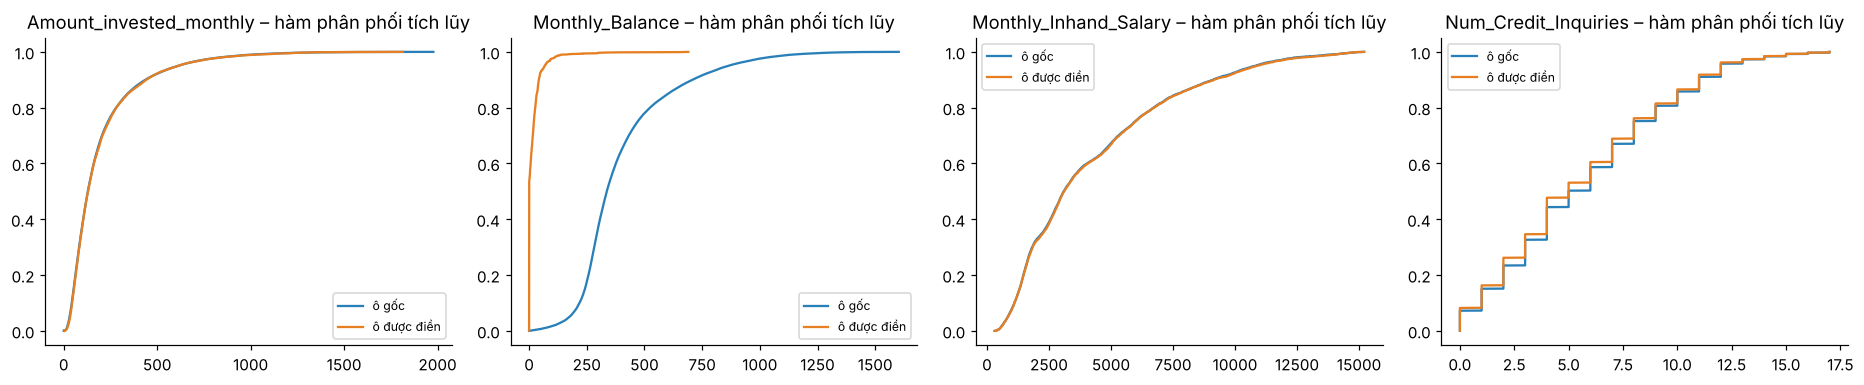

In [3]:
fig, ax = plt.subplots(1, 4, figsize=(17, 3.6))
for a, c in zip(ax, ['Amount_invested_monthly', 'Monthly_Balance', 'Monthly_Inhand_Salary', 'Num_Credit_Inquiries']):
    imp = d3[c].isna()
    for m, lab, col in [(~imp, 'ô gốc', '#2980b9'), (imp, 'ô được điền', '#e67e22')]:
        v = np.sort(clean.loc[m, c].values); a.plot(v, np.arange(1, len(v) + 1) / len(v), label=lab, color=col)
    a.set_title(c + ' – hàm phân phối tích lũy'); a.legend(fontsize=8)
plt.tight_layout(); plt.show()

**Đọc kết quả (phần 1).** Mười một trong mười hai cột có phân phối ô được điền **gần như trùng** ô gốc (KS ≤ 0,08) và σ gần bằng nhau – tức cách điền **không co cụm** giá trị về trung bình. Các cột điền bằng luật/`nearest`/`cust_median` (thu nhập, lãi suất, số tài khoản, lương…) và cả `Amount_invested_monthly` (điền bằng mô hình) đều như vậy.

**Ngoại lệ đáng điều tra: `Monthly_Balance`** có KS > 0,9 – ô được điền *khác hẳn* ô gốc (trung vị 0 so với khoảng 337; σ 42 so với 214). Đây có thể là lỗi của mô hình điền, hoặc là ô thiếu thật sự thuộc một nhóm khách *khác*. Phải phân biệt hai khả năng này trước khi kết luận.

In [4]:
# (a) Các dòng bị thiếu Monthly_Balance có "giống" các dòng còn lại không?
mb_imp = d3['Monthly_Balance'].isna()
raw_pb = raw['Payment_Behaviour']
tbl = pd.DataFrame({
    'trung vị lương tháng': [clean.loc[~mb_imp, 'Monthly_Inhand_Salary'].median(), clean.loc[mb_imp, 'Monthly_Inhand_Salary'].median()],
    'trung vị đầu tư tháng': [clean.loc[~mb_imp, 'Amount_invested_monthly'].median(), clean.loc[mb_imp, 'Amount_invested_monthly'].median()],
    '% dòng "Low_spent_Small_value"': [(raw_pb[~mb_imp] == 'Low_spent_Small_value_payments').mean() * 100, (raw_pb[mb_imp] == 'Low_spent_Small_value_payments').mean() * 100],
    '% dòng "High_spent_*"': [raw_pb[~mb_imp].str.startswith('High').mean() * 100, raw_pb[mb_imp].str.startswith('High').mean() * 100],
    '% nhãn Poor': [(clean.loc[~mb_imp, 'Credit_Score'] == 'Poor').mean() * 100, (clean.loc[mb_imp, 'Credit_Score'] == 'Poor').mean() * 100],
}, index=['dòng còn Monthly_Balance', f'dòng bị thiếu (n={int(mb_imp.sum()):,})']).round(1)
tbl

,trung vị lương tháng,trung vị đầu tư tháng,"% dòng ""Low_spent_Small_value""","% dòng ""High_spent_*""",% nhãn Poor
dòng còn Monthly_Balance,3058.6,127.4,24.9,43.1,29.0
"dòng bị thiếu (n=1,209)",6705.1,750.8,73.0,0.7,28.8


Các dòng bị thiếu **không phải mẫu ngẫu nhiên**: lương và tiền đầu tư cao hơn nhiều, và hầu hết thuộc nhóm "chi tiêu thấp" (chỉ ~1% là "High_spent" so với 43% ở nhóm còn lại) – nghĩa là thiếu dữ liệu **phụ thuộc vào các cột khác** (ít nhất là MAR), không phải MCAR. Vì thế so sánh với *toàn bộ* ô gốc là không công bằng; phải so sánh ở **cùng vùng đặc trưng**. Hai phép kiểm tra:
1. thí nghiệm che giá trị **chỉ trong vùng lương cao** (nơi các ô thiếu tập trung): mô hình điền có còn chính xác không?
2. so sánh giá trị đã điền với **các dòng gốc giống nhất** (láng giềng gần nhất theo lương, tiền đầu tư, EMI và mức chi tiêu).

In [5]:
# (b) Thí nghiệm che giá trị chỉ trong vùng lương cao (>6000/tháng) – so sánh điền theo giá trị và theo tỷ lệ
sal = cc.fill_numeric(d3, 'Monthly_Inhand_Salary', 'nearest')
sd = d3['Monthly_Balance'].std(); rows = []
for seed in (0, 1, 2):
    rng = np.random.default_rng(seed); known = d3.index[d3['Monthly_Balance'].notna()]
    idx = rng.choice(known, size=int(0.1 * len(known)), replace=False)
    m = d3.copy(); m.loc[idx, 'Monthly_Balance'] = np.nan
    hi = sal.loc[idx] > 6000
    for strat in ['cust_median', 'model', 'model_ratio']:
        e = (d3.loc[idx, 'Monthly_Balance'] - cc.fill_numeric(m, 'Monthly_Balance', strat).loc[idx]).abs() / sd
        rows.append({'chiến lược': strat, 'seed': seed, 'NMAE – lương ≤ 6000': e[~hi].mean(), 'NMAE – lương > 6000': e[hi].mean(), 'số ô lương cao': int(hi.sum())})
tab_hi = pd.DataFrame(rows).groupby('chiến lược').mean().drop(columns='seed').loc[['cust_median', 'model', 'model_ratio']]
tab_hi.round(3)

,NMAE – lương ≤ 6000,NMAE – lương > 6000,số ô lương cao
chiến lược,,,
cust_median,0.282,0.919,2418.667
model,0.070,0.154,2418.667
model_ratio,0.055,0.136,2418.667


In [6]:
# (c) So với các dòng gốc giống nhất: với mỗi ô Monthly_Balance được điền, lấy trung vị của 20 dòng gốc gần nhất
#     (chuẩn hóa lương, tiền đầu tư, EMI; ép cùng nhóm chi tiêu thấp/cao) và xem giá trị điền nằm trên hay dưới
from sklearn.neighbors import NearestNeighbors
F = ['Monthly_Inhand_Salary', 'Amount_invested_monthly', 'Total_EMI_per_month']
Z = clean[F].copy(); Z['low'] = clean['Payment_Behaviour'].str.startswith('Low').astype(float) * 3000
Z = (Z - Z.mean()) / Z.std()
obs_idx = np.where(~mb_imp.values)[0]; imp_idx = np.where(mb_imp.values)[0]
nn = NearestNeighbors(n_neighbors=20).fit(Z.iloc[obs_idx])
_, ind = nn.kneighbors(Z.iloc[imp_idx])
y_obs = clean['Monthly_Balance'].values[obs_idx]
neigh = np.median(y_obs[ind], axis=1); imputed = clean['Monthly_Balance'].values[imp_idx]
# Kiểm tra chuẩn: cùng thủ tục trên 1.500 dòng GỐC (đã biết đáp án) – láng giềng có thiên lệch không?
rs = np.random.default_rng(0).choice(obs_idx, 1500, replace=False); rest = np.setdiff1d(obs_idx, rs)
nn2 = NearestNeighbors(n_neighbors=20).fit(Z.iloc[rest]); _, ind2 = nn2.kneighbors(Z.iloc[rs])
neigh2 = np.median(clean['Monthly_Balance'].values[rest][ind2], axis=1); truth2 = clean['Monthly_Balance'].values[rs]
print(f'Ô được điền: trung vị giá trị điền = {np.median(imputed):.1f} | trung vị láng giềng gốc = {np.median(neigh):.1f}')
print(f'Tỷ lệ ô được điền THẤP hơn láng giềng gốc: {np.mean(imputed < neigh):.1%}')
print(f'(đối chứng) với dòng gốc đã biết đáp án, tỷ lệ đáp án thấp hơn láng giềng: {np.mean(truth2 < neigh2):.1%}  → thủ tục láng giềng tự nó không thiên lệch')

Ô được điền: trung vị giá trị điền = 0.0 | trung vị láng giềng gốc = 44.5
Tỷ lệ ô được điền THẤP hơn láng giềng gốc: 97.1%
(đối chứng) với dòng gốc đã biết đáp án, tỷ lệ đáp án thấp hơn láng giềng: 47.9%  → thủ tục láng giềng tự nó không thiên lệch


In [7]:
# (d) Mức sàn: dữ liệu gốc không có số dư <= 0, nhưng mô hình dự đoán <= 0 cho nhiều ô thiếu (đã bị chặn dưới ở 0)
obs_mb = clean.loc[~mb_imp, 'Monthly_Balance']; imp_mb = clean.loc[mb_imp, 'Monthly_Balance']
print(f'Ô gốc: nhỏ nhất = {obs_mb.min():.4f} | số ô <= 0: {(obs_mb <= 0).sum()} | số ô < 5: {(obs_mb < 5).sum()} ({(obs_mb < 5).mean():.2%})')
print(f'Ô được điền: {(imp_mb == 0).mean():.1%} nằm đúng ở mức sàn 0 (mô hình dự đoán số dư <= 0), {(imp_mb < 5).mean():.1%} < 5')

Ô gốc: nhỏ nhất = 0.0078 | số ô <= 0: 0 | số ô < 5: 51 (0.05%)
Ô được điền: 52.6% nằm đúng ở mức sàn 0 (mô hình dự đoán số dư <= 0), 58.1% < 5


**Kết luận về `Monthly_Balance` (phải nói rõ khi báo cáo).**
- Mô hình điền **chính xác trên các ô đã biết**, kể cả ở vùng lương cao (bảng (b)); điền theo *tỷ lệ so với lương* tốt hơn điền theo giá trị tuyệt đối.
- Khoảng cách phân phối lớn (KS > 0,9) chủ yếu do **ô thiếu thuộc nhóm khách khác** (lương cao, đầu tư nhiều, chi tiêu thấp), chứ không phải do mô hình bóp méo các giá trị bình thường.
- **Nhưng** ở các dòng đó mô hình dự đoán số dư **bằng hoặc dưới 0** cho hơn một nửa số ô (bị chặn ở 0), trong khi dữ liệu gốc **không có một số dư nào ≤ 0** (nhỏ nhất ≈ 0,008, chỉ ~0,05% ô dưới 5). Giá trị điền cũng thấp hơn các dòng gốc "giống nhất" ở gần như mọi ô, trong khi đối chứng cho thấy thủ tục so sánh không thiên lệch. Dấu hiệu này **phù hợp với thiếu không ngẫu nhiên (MNAR)**: số dư có thể bị bỏ trống *chính vì* nó ≤ 0 (khách chi tiêu + đầu tư hết lương).
- Đây là **giả thuyết, không phải kết luận**: dữ liệu không có đáp án thật cho các ô thiếu nên không thể kiểm chứng. Lựa chọn trong pipeline (chặn dưới ở 0 – giả định ít nhất) có thể chênh với giá trị thật tới mức vài trăm ở một số ít dòng.
- Phạm vi ảnh hưởng nhỏ: ~1,2% số dòng (≈ 0,6% dòng nằm đúng ở mức sàn), một cột trong 21 cột, và tỷ lệ nhãn Poor/Standard/Good ở các dòng này gần như bằng toàn bộ dữ liệu (xem bảng (a)). Mục "phân tích lỗi" ở notebook 4 kiểm tra mô hình có sai nhiều hơn ở các dòng này không.

**Kết luận chung của phần 3.1:** điền thiếu không co cụm phân phối ở 11/12 cột; ngoại lệ `Monthly_Balance` có cấu trúc thiếu đặc biệt (nghi MNAR) và được ghi nhận như một hạn chế.

Kiểm tra cuối: **việc điền có tự tạo ra tín hiệu nhãn giả không?** Nếu quan hệ với nhãn ở ô được điền *khác hẳn* ô gốc thì cách điền đã làm méo dữ liệu. So sánh tương quan Spearman với nhãn (Poor < Standard < Good):

In [8]:
y = clean.Credit_Score.map(ORD)
rows = []
for c in ['Amount_invested_monthly', 'Monthly_Balance', 'Monthly_Inhand_Salary', 'Num_Credit_Inquiries', 'Num_of_Delayed_Payment',
          'Changed_Credit_Limit', 'Total_EMI_per_month', 'Interest_Rate', 'Num_Bank_Accounts']:
    imp = d3[c].isna()
    rows.append({'cột': c, 'Spearman (ô gốc)': round(stats.spearmanr(clean.loc[~imp, c], y[~imp])[0], 3),
                 'Spearman (ô được điền)': round(stats.spearmanr(clean.loc[imp, c], y[imp])[0], 3)})
tab = pd.DataFrame(rows).set_index('cột'); tab['chênh lệch'] = (tab.iloc[:, 1] - tab.iloc[:, 0]).round(3); tab

,Spearman (ô gốc),Spearman (ô được điền),chênh lệch
cột,,,
Amount_invested_monthly,0.126,0.124,-0.002
Monthly_Balance,0.225,-0.008,-0.233
Monthly_Inhand_Salary,0.203,0.205,0.002
Num_Credit_Inquiries,-0.438,-0.454,-0.016
Num_of_Delayed_Payment,-0.362,-0.395,-0.033
Changed_Credit_Limit,-0.157,-0.143,0.014
Total_EMI_per_month,-0.083,-0.096,-0.013
Interest_Rate,-0.481,-0.514,-0.033
Num_Bank_Accounts,-0.387,-0.343,0.044


Ở các cột, hệ số tương quan với nhãn ở ô được điền **cùng dấu và cùng bậc độ lớn** với ô gốc (và không cao hơn một cách đáng ngờ ở các cột điền bằng mô hình – điều sẽ xảy ra nếu nhãn "lọt" vào quá trình điền; mà pipeline không hề dùng nhãn). **Ngoại lệ là `Monthly_Balance`** (≈ 0 ở ô được điền so với 0,22 ở ô gốc): hơn một nửa ô được điền cùng bằng 0 nên hạng bị trùng, hệ số này không còn ý nghĩa, và nó phản ánh đúng nhóm khách đặc biệt đã phân tích ở trên chứ không phải nhãn lọt vào. → Việc điền thiếu **không tạo tín hiệu nhãn giả** (không có ô nào có tương quan *cao hơn* ô gốc).

## 3.2 Quan hệ với nhãn: trước và sau làm sạch
So sánh **độ lớn hiệu ứng** (ε² Kruskal–Wallis cho biến số; Cramér's V cho biến phân loại) giữa
- *trước*: giá trị hợp lệ của dữ liệu gốc, mỗi đặc trưng chỉ dùng các dòng không lỗi (kết quả đã lưu ở notebook 1, mục 1.7);
- *sau*: dữ liệu sạch, đầy đủ 100.000 dòng.

In [9]:
def effect_numeric(d, cols):
    rows = []; yy = d.Credit_Score
    for c in cols:
        H, p = stats.kruskal(*[d.loc[yy == k, c] for k in ORDER])
        rows.append({'đặc trưng': c, 'ε² (sau)': H / (len(d) - 1), 'Spearman (sau)': stats.spearmanr(d[c], yy.map(ORD))[0]})
    return pd.DataFrame(rows).set_index('đặc trưng')

def cramers_v(a, b):
    ct = pd.crosstab(a, b); chi2 = stats.chi2_contingency(ct)[0]; n = ct.values.sum()
    return np.sqrt(chi2 / (n * (min(ct.shape) - 1)))

bef_num = pd.read_csv('../data/reports/eda_effect_numeric_before.csv', index_col=0)
aft_num = effect_numeric(clean, [c for c in bef_num.index if c in clean.columns])
cmp_num = bef_num[['ε² (Kruskal)', 'Spearman với nhãn']].join(aft_num[['ε² (sau)', 'Spearman (sau)']])
cmp_num.columns = ['ε² trước', 'Spearman trước', 'ε² sau', 'Spearman sau']
cmp_num['ε² thay đổi (%)'] = ((cmp_num['ε² sau'] / cmp_num['ε² trước'] - 1) * 100).round(1)
cmp_num.sort_values('ε² sau', ascending=False).round(4)

,ε² trước,Spearman trước,ε² sau,Spearman sau,ε² thay đổi (%)
đặc trưng,,,,,
Interest_Rate,0.2334,-0.4809,0.2341,-0.4816,0.3
Delay_from_due_date,0.1946,-0.4379,0.1946,-0.4379,0.0
Outstanding_Debt,0.1940,-0.4338,0.1940,-0.4338,0.0
Num_Credit_Inquiries,0.1920,-0.4379,0.1925,-0.4385,0.3
Num_Bank_Accounts,0.1575,-0.3874,0.1571,-0.3867,-0.3
Num_Credit_Card,0.1487,-0.3850,0.1494,-0.3859,0.4
Num_of_Delayed_Payment,0.1439,-0.3617,0.1466,-0.3650,1.9
Num_of_Loan,0.1248,-0.3531,0.1256,-0.3542,0.7
Changed_Credit_Limit,0.0534,-0.1573,0.0535,-0.1570,0.3


,Cramér V trước,Cramér V sau,thay đổi (%)
Credit_Mix,0.4022,0.4499,11.9
Month,0.0318,0.0318,0.0
Occupation,0.0292,0.0301,3.1
Payment_Behaviour,0.0846,0.0846,0.0
Payment_of_Min_Amount,0.3132,0.3132,0.0


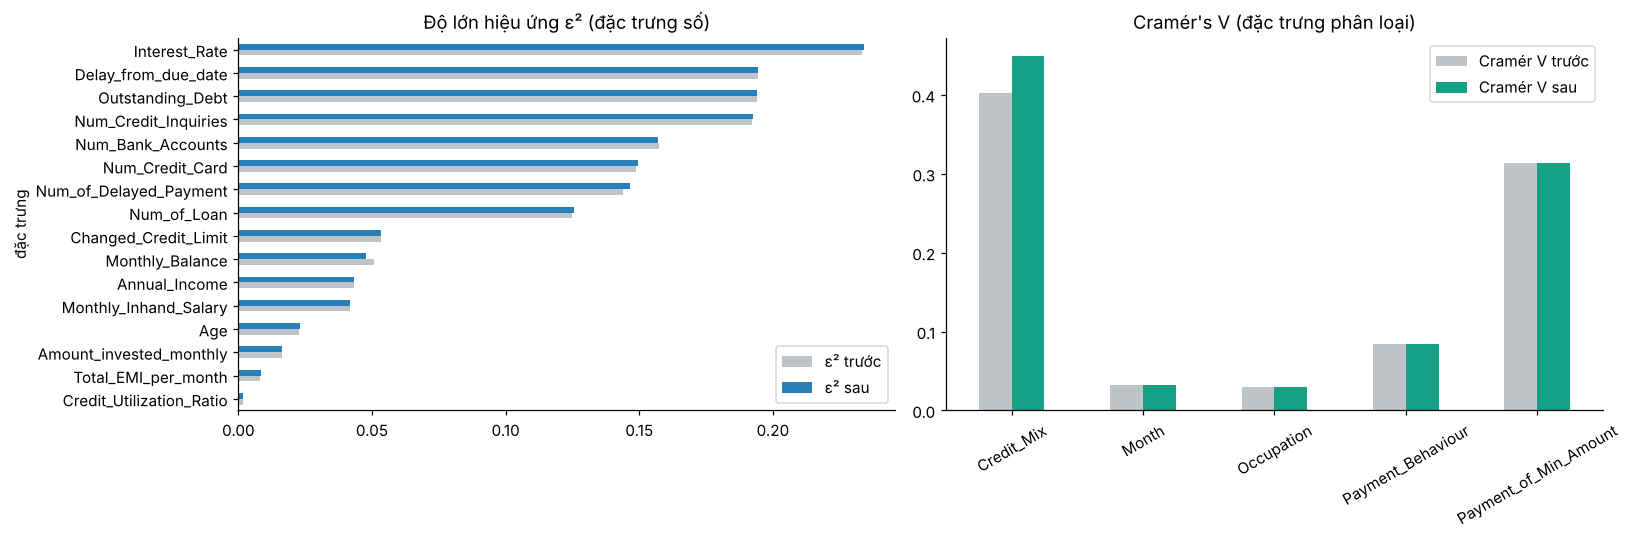

In [10]:
bef_cat = pd.read_csv('../data/reports/eda_effect_categorical_before.csv', index_col=0)
aft_cat = pd.Series({c: cramers_v(clean[c], clean.Credit_Score) for c in ['Credit_Mix', 'Payment_of_Min_Amount', 'Payment_Behaviour', 'Occupation', 'Month']})
cmp_cat = pd.DataFrame({'Cramér V trước': bef_cat['Cramér V'], 'Cramér V sau': aft_cat}).round(4); cmp_cat['thay đổi (%)'] = ((cmp_cat.iloc[:, 1] / cmp_cat.iloc[:, 0] - 1) * 100).round(1)
display(cmp_cat)
fig, ax = plt.subplots(1, 2, figsize=(15, 5))
cmp_num.sort_values('ε² sau')[['ε² trước', 'ε² sau']].plot(kind='barh', ax=ax[0], color=['#bdc3c7', '#2980b9']); ax[0].set_title('Độ lớn hiệu ứng ε² (đặc trưng số)')
cmp_cat[['Cramér V trước', 'Cramér V sau']].plot(kind='bar', ax=ax[1], color=['#bdc3c7', '#16a085'], rot=30); ax[1].set_title("Cramér's V (đặc trưng phân loại)")
plt.tight_layout(); plt.show()

**Đọc kết quả.** Sau làm sạch:
- Thứ tự mức liên quan **giữ nguyên** (lãi suất, độ trễ, nợ, truy vấn tín dụng… vẫn đứng đầu) → không có quan hệ thật nào bị xóa.
- Các cột được khôi phục chính xác **mạnh lên** rõ rệt ở những cột có nhiều ô lỗi: đáng chú ý nhất là `Credit_Mix` (Cramér V tăng mạnh vì nhóm placeholder `_` – 20% dòng, trước đây là một "nhóm" vô nghĩa – được trả về đúng giá trị thật) và `Num_of_Loan`, `Num_of_Delayed_Payment`, `Num_Credit_Inquiries`.
- Các cột vốn không liên quan (`Occupation`, `Month`) vẫn không liên quan → làm sạch **không bịa ra** quan hệ.

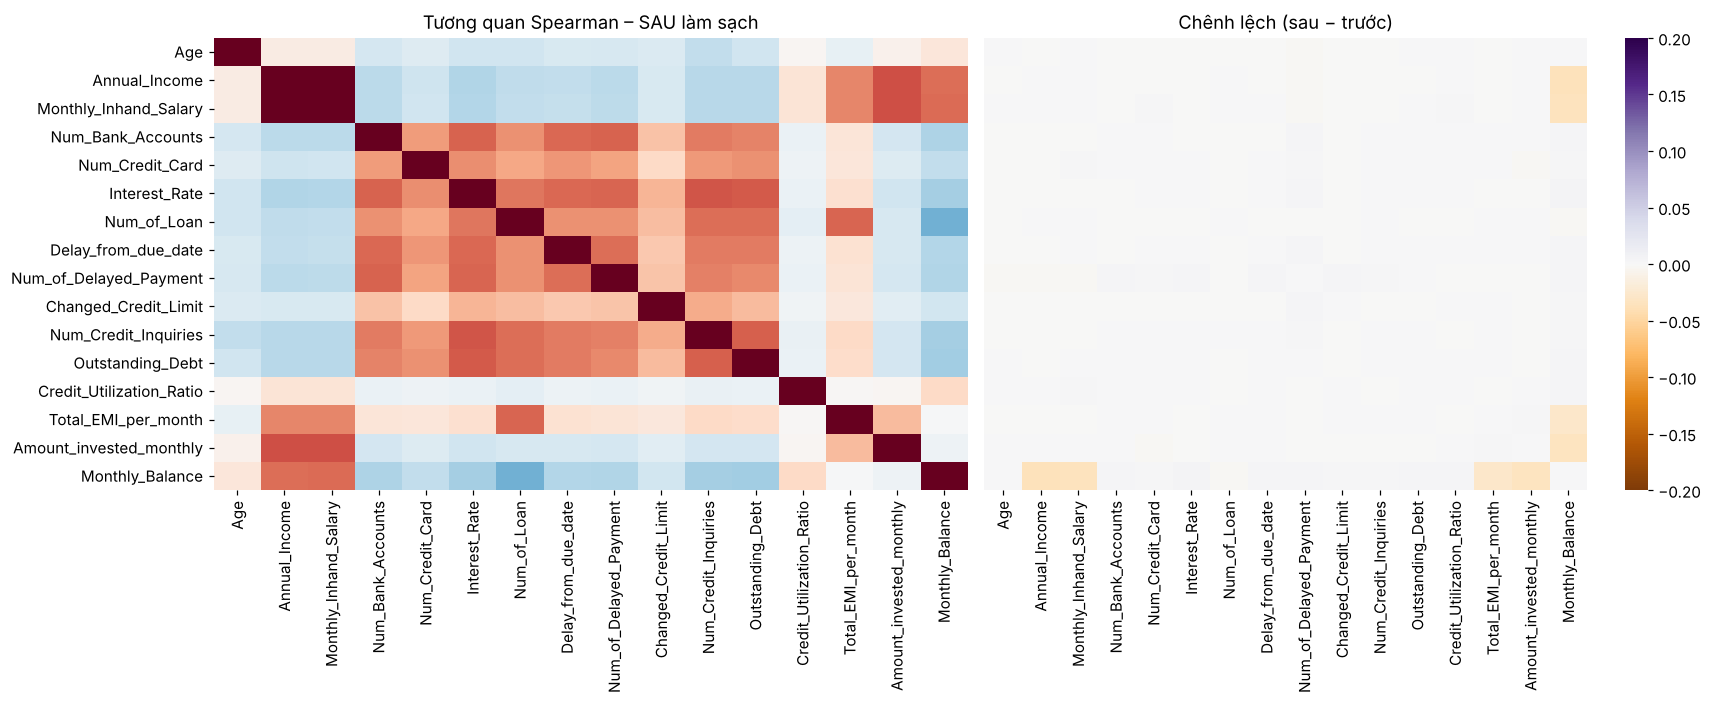

Chênh lệch tuyệt đối trung bình giữa 120 cặp tương quan: 0.002  | lớn nhất: 0.036


In [11]:
# Cấu trúc tương quan giữa các đặc trưng có được giữ không?
NUM = ['Age', 'Annual_Income', 'Monthly_Inhand_Salary', 'Num_Bank_Accounts', 'Num_Credit_Card', 'Interest_Rate', 'Num_of_Loan', 'Delay_from_due_date',
       'Num_of_Delayed_Payment', 'Changed_Credit_Limit', 'Num_Credit_Inquiries', 'Outstanding_Debt', 'Credit_Utilization_Ratio', 'Total_EMI_per_month',
       'Amount_invested_monthly', 'Monthly_Balance']
view = cc.mark_invalid(cc.strip_numeric_text(cc.mark_placeholders(cc.add_month_num(raw))))
c_before = view[NUM].corr(method='spearman'); c_after = clean[NUM].corr(method='spearman')
diff = (c_after - c_before)
fig, ax = plt.subplots(1, 2, figsize=(16, 6.5))
sns.heatmap(c_after, cmap='RdBu_r', center=0, vmin=-1, vmax=1, ax=ax[0], cbar=False, xticklabels=True, yticklabels=True); ax[0].set_title('Tương quan Spearman – SAU làm sạch')
sns.heatmap(diff, cmap='PuOr', center=0, vmin=-.2, vmax=.2, ax=ax[1], xticklabels=True, yticklabels=False); ax[1].set_title('Chênh lệch (sau − trước)')
plt.tight_layout(); plt.show()
off = diff.values[np.triu_indices(len(NUM), 1)]
print(f'Chênh lệch tuyệt đối trung bình giữa 120 cặp tương quan: {np.abs(off).mean():.3f}  | lớn nhất: {np.abs(off).max():.3f}')

Chênh lệch tương quan giữa các đặc trưng **rất nhỏ** (trung bình vài phần trăm) → cấu trúc phụ thuộc lẫn nhau được giữ nguyên; những thay đổi nhỏ chủ yếu ở các cặp có cột được điền bằng mô hình/`nearest`. Dữ liệu sạch vừa **sạch hơn** vừa **trung thành** với dữ liệu gốc.

## 3.3 Tạo đặc trưng (Feature Engineering)

Dữ liệu sạch đã đủ để chạy mô hình, nhưng ta còn khai thác được hai nguồn thông tin mà các cột thô chưa diễn đạt: **quan hệ tài chính** (tỷ số) và **cấu trúc theo thời gian** của từng khách. Có 5 nhóm, mỗi nhóm có lý do:

| Nhóm | Đặc trưng | Lý do |
|---|---|---|
| **RATIO** | `Debt_to_Income`, `EMI_to_Salary`, `Invest_to_Salary`, `Balance_to_Salary`, `Implied_Spend_Ratio`, `Debt_per_Loan`, `Has_Loan` | Nợ 3.000 là gánh nặng với người thu 20.000/năm nhưng nhẹ với người thu 150.000. Mô hình cần *tỷ lệ*, không chỉ số tuyệt đối. `Implied_Spend_Ratio` = phần lương không giải thích được bởi EMI, đầu tư và số dư ≈ chi tiêu |
| **LOAN** | 9 cờ `Loan_*` | `Type_of_Loan` là chuỗi nhiều giá trị; tách ra để mô hình dùng được từng loại vay (vd. vay "Payday" rủi ro hơn "Home Equity") |
| **PB_SPLIT** | `Spend_Level`, `Payment_Size` | `Payment_Behaviour` ghép hai ý (mức chi tiêu × độ lớn khoản trả); tách ra để chia sẻ thống kê giữa các tổ hợp |
| **LAG** *(nhân quả)* | `*_prev`, `*_delta`, `*_expmean` cho độ trễ, số lần trả chậm, tỷ lệ sử dụng hạn mức, số lần truy vấn | Xu hướng: tháng này tệ hơn tháng trước không? Chỉ dùng tháng hiện tại và **các tháng trước** → dùng được khi dự đoán thời gian thực |
| **CUST_AGG** *(nhìn lại)* | trung bình, độ lệch chuẩn trên 8 tháng của 7 chỉ số; tỷ lệ tháng không trả mức tối thiểu | Hành vi *đặc trưng* của khách, ổn định hơn một tháng đơn lẻ. **Dùng cả các tháng sau** → chỉ hợp lệ khi đánh giá "nhìn lại" trọn 8 tháng |

Phân biệt LAG (nhân quả) và CUST_AGG (nhìn lại) là cần thiết để không báo cáo một kết quả mà trong thực tế không thể có (chưa biết các tháng tương lai).

In [12]:
def add_ratio_features(d):
    """Tỷ số tài chính theo từng dòng. Mẫu số được chặn dưới để tránh chia cho 0."""
    d = d.copy()
    salary = d['Monthly_Inhand_Salary'].clip(lower=1)
    d['Debt_to_Income'] = d['Outstanding_Debt'] / d['Annual_Income']
    d['EMI_to_Salary'] = d['Total_EMI_per_month'] / salary
    d['Invest_to_Salary'] = d['Amount_invested_monthly'] / salary
    d['Balance_to_Salary'] = d['Monthly_Balance'] / salary
    d['Implied_Spend_Ratio'] = (salary - d['Total_EMI_per_month'] - d['Amount_invested_monthly'] - d['Monthly_Balance']) / salary
    d['Debt_per_Loan'] = d['Outstanding_Debt'] / d['Num_of_Loan'].clip(lower=1)
    d['Has_Loan'] = (d['Num_of_Loan'] > 0).astype(int)
    return d

def add_loan_flags(d):
    """Mỗi loại khoản vay -> cột 0/1 (tách chuỗi 'Auto Loan, Credit-Builder Loan, and Home Equity Loan')."""
    d = d.copy()
    uniq = d['Type_of_Loan'].unique()
    parsed = {u: {p.strip() for p in re.split(r',\s*', str(u).replace(' and ', ' '))} for u in uniq}
    for t, name in zip(LOAN_TYPES, LOAN):
        d[name] = d['Type_of_Loan'].map(lambda u: int(t in parsed[u]))
    return d

def add_payment_split(d):
    """Payment_Behaviour = '<Mức chi tiêu>_spent_<Độ lớn>_value_payments' -> hai cột riêng (Unknown giữ nguyên)."""
    d = d.copy()
    d['Spend_Level'] = d['Payment_Behaviour'].str.extract(r'^(High|Low)_spent')[0].fillna('Unknown')
    d['Payment_Size'] = d['Payment_Behaviour'].str.extract(r'_(Small|Medium|Large)_value')[0].fillna('Unknown')
    return d

def add_lag_features(d):
    """Đặc trưng nhân quả: giá trị tháng trước, thay đổi so với tháng trước, trung bình lũy kế tới tháng hiện tại.
    Tháng đầu tiên (không có tháng trước) dùng chính giá trị hiện tại."""
    d = d.copy()
    g = d.groupby('Customer_ID')
    for c in LAG_COLS:
        d[f'{c}_prev'] = g[c].shift(1).fillna(d[c])
        d[f'{c}_delta'] = d[c] - d[f'{c}_prev']
        d[f'{c}_expmean'] = g[c].cumsum() / d['Month_Num']
    return d

def add_customer_features(d):
    """Thống kê trên cả 8 tháng của khách (trung bình, độ lệch chuẩn, tỷ lệ tháng không trả mức tối thiểu).
    Lưu ý: dùng thông tin của các tháng SAU tháng hiện tại -> chỉ hợp lệ khi đánh giá 'nhìn lại' trọn 8 tháng."""
    d = d.copy()
    g = d.groupby('Customer_ID')
    for c in AGG_COLS:
        d[f'{c}_cust_mean'] = g[c].transform('mean')
        d[f'{c}_cust_std'] = g[c].transform('std')
    d['MinPay_No_share'] = (d['Payment_of_Min_Amount'] == 'No').groupby(d['Customer_ID']).transform('mean')
    return d

def build_features(clean_df):
    """clean_df (output của credit_cleaning.clean) -> bảng có thêm mọi nhóm đặc trưng."""
    d = add_ratio_features(clean_df)
    d = add_loan_flags(d)
    d = add_payment_split(d)
    d = add_lag_features(d)
    d = add_customer_features(d)
    return d

In [13]:
feat = cf.build_features(clean)
new_cols = [c for g in ['RATIO', 'LOAN', 'PB_SPLIT', 'LAG', 'CUST_AGG'] for c in cf.FEATURE_GROUPS[g]]
print(f'Bảng đặc trưng: {feat.shape}  (+{len(new_cols)} cột mới so với dữ liệu sạch)')
print(pd.Series({g: len(v) for g, v in cf.FEATURE_GROUPS.items()}, name='số cột').to_frame().T.to_string())
num_new = [c for c in new_cols if c not in cf.CATEGORICAL]
assert np.isfinite(feat[num_new].values).all(), 'Có NaN/inf trong đặc trưng mới'
print('Không có NaN / inf trong đặc trưng mới ✓')
feat[cf.RATIO + cf.CUST_AGG[:4]].describe().T[['min', '25%', '50%', '75%', 'max']].round(3)

Bảng đặc trưng: (100000, 74)  (+45 cột mới so với dữ liệu sạch)
        BASE  RATIO  LOAN  PB_SPLIT  LAG  CUST_AGG
số cột    21      7     9         2   12        15
Không có NaN / inf trong đặc trưng mới ✓


,min,25%,50%,75%,max
Debt_to_Income,0.000,0.010,0.028,0.070,0.683
EMI_to_Salary,0.000,0.012,0.024,0.040,0.225
Invest_to_Salary,0.000,0.025,0.044,0.075,0.154
Balance_to_Salary,0.000,0.080,0.115,0.179,0.876
Implied_Spend_Ratio,-0.055,0.726,0.812,0.855,0.888
Debt_per_Loan,0.049,215.121,375.587,617.916,1498.410
Has_Loan,0.000,1.000,1.000,1.000,1.000
Delay_from_due_date_cust_mean,-2.000,9.875,17.875,28.000,63.250
Delay_from_due_date_cust_std,0.000,1.061,1.642,2.078,3.926
Num_of_Delayed_Payment_cust_mean,0.000,9.000,13.750,18.250,26.375


## 3.4 Đặc trưng mới có thật sự hữu ích không?
Tạo đặc trưng dễ, quan trọng là **đo**. Ba phép đo độc lập:
1. Độ lớn hiệu ứng ε² (Kruskal) – mức phân tách ba nhãn;
2. **Mutual information** với nhãn (bắt được cả quan hệ phi tuyến);
3. **Độ trùng lặp** với các đặc trưng gốc (đặc trưng mới mà tương quan ≈ 1 với cột gốc thì không thêm thông tin).

In [14]:
allnum = cf.BASE_NUM + [c for c in num_new]
eff = effect_numeric(feat, allnum)
eff['nhóm'] = [next((g for g, cols in cf.FEATURE_GROUPS.items() if c in cols), '?') for c in eff.index]
eff = eff.sort_values('ε² (sau)', ascending=False)
eff.round(4).head(25)

,ε² (sau),Spearman (sau),nhóm
đặc trưng,,,
Interest_Rate,0.2341,-0.4816,BASE
Num_Credit_Inquiries_expmean,0.2113,-0.4595,LAG
Num_Credit_Inquiries_cust_mean,0.2066,-0.4545,CUST_AGG
MinPay_No_share,0.2059,0.4175,CUST_AGG
Delay_from_due_date_cust_mean,0.1980,-0.4416,CUST_AGG
Num_Credit_Inquiries_prev,0.1977,-0.4443,LAG
Delay_from_due_date_expmean,0.1973,-0.4409,LAG
Delay_from_due_date_prev,0.1952,-0.4387,LAG
Delay_from_due_date,0.1946,-0.4379,BASE


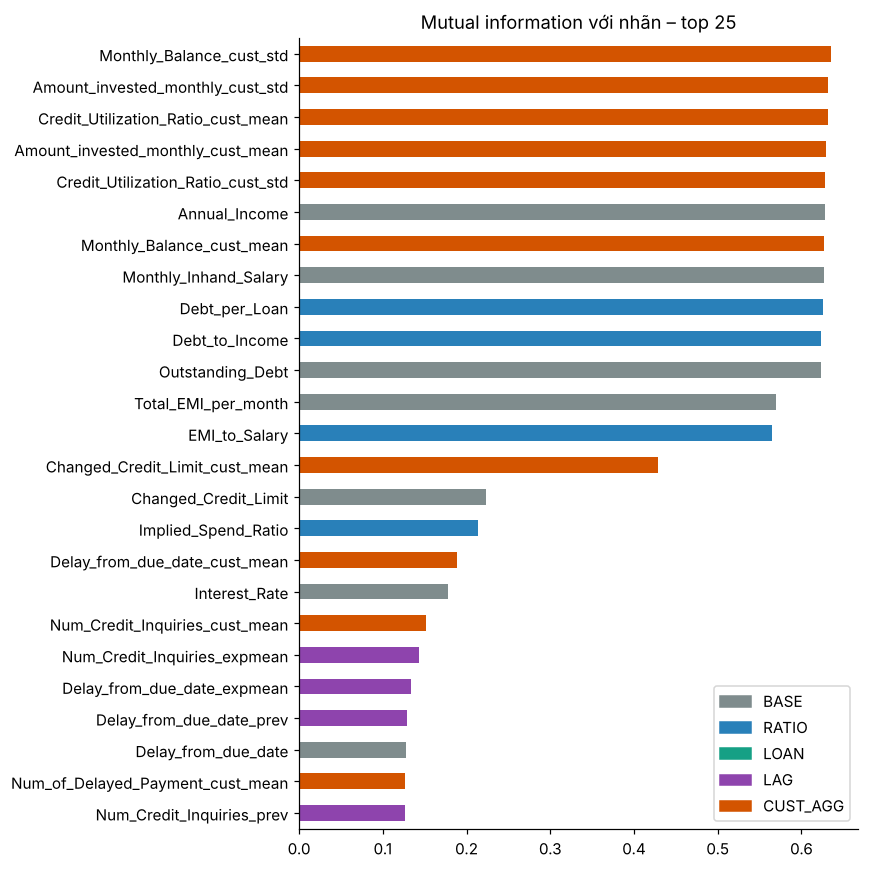

,MI trung bình theo nhóm,MI lớn nhất,số cột
CUST_AGG,0.3253,0.6357,15
BASE,0.2158,0.6278,17
RATIO,0.2947,0.6261,7
LAG,0.0651,0.1430,12
LOAN,0.0111,0.0174,9


In [15]:
# Mutual information trên mẫu 30.000 dòng (lấy theo khách để không lẫn dòng của cùng một người)
rng = np.random.default_rng(0)
custs = rng.choice(feat.Customer_ID.unique(), size=3750, replace=False)
samp = feat[feat.Customer_ID.isin(custs)]
mi = pd.Series(mutual_info_classif(samp[allnum], samp.Credit_Score, random_state=0), index=allnum).sort_values(ascending=False)
grp = pd.Series([next((g for g, cols in cf.FEATURE_GROUPS.items() if c in cols), '?') for c in mi.index], index=mi.index)
colors = grp.map({'BASE': '#7f8c8d', 'RATIO': '#2980b9', 'LOAN': '#16a085', 'LAG': '#8e44ad', 'CUST_AGG': '#d35400'})
fig, ax = plt.subplots(figsize=(8, 8)); mi.head(25)[::-1].plot(kind='barh', ax=ax, color=colors.head(25)[::-1]); ax.set_title('Mutual information với nhãn – top 25')
import matplotlib.patches as mp
ax.legend(handles=[mp.Patch(color=v, label=k) for k, v in {'BASE': '#7f8c8d', 'RATIO': '#2980b9', 'LOAN': '#16a085', 'LAG': '#8e44ad', 'CUST_AGG': '#d35400'}.items()], loc='lower right')
plt.tight_layout(); plt.show()
pd.DataFrame({'MI trung bình theo nhóm': mi.groupby(grp).mean().round(4), 'MI lớn nhất': mi.groupby(grp).max().round(4), 'số cột': grp.value_counts()}).sort_values('MI lớn nhất', ascending=False)

In [16]:
# Độ trùng lặp: cặp đặc trưng có |ρ| > 0,95 (một bên là đặc trưng mới)
cm = feat[allnum].corr(method='spearman').abs(); tri = cm.where(np.triu(np.ones(cm.shape, dtype=bool), 1)).stack()
dup = tri[tri > 0.95].sort_values(ascending=False)
dup = dup[[(a in num_new) or (b in num_new) for a, b in dup.index]]
print(f'{len(dup)} cặp có |ρ| > 0,95 liên quan đặc trưng mới:'); dup.round(3).to_frame('|ρ|')

23 cặp có |ρ| > 0,95 liên quan đặc trưng mới:


,,|ρ|
Delay_from_due_date_expmean,Delay_from_due_date_cust_mean,0.998
Num_of_Delayed_Payment_expmean,Num_of_Delayed_Payment_cust_mean,0.996
Monthly_Balance_cust_std,Amount_invested_monthly_cust_std,0.994
Delay_from_due_date,Delay_from_due_date_expmean,0.993
Delay_from_due_date_prev,Delay_from_due_date_expmean,0.993
Delay_from_due_date,Delay_from_due_date_cust_mean,0.990
Delay_from_due_date_prev,Delay_from_due_date_cust_mean,0.990
Num_of_Delayed_Payment_prev,Num_of_Delayed_Payment_expmean,0.987
Num_of_Delayed_Payment,Num_of_Delayed_Payment_expmean,0.987
Num_Credit_Inquiries_prev,Num_Credit_Inquiries_expmean,0.984


**Kết luận về đặc trưng**
- Nhóm **CUST_AGG** (hành vi trung bình của khách qua 8 tháng) có mức liên hệ **đơn lẻ** với nhãn mạnh nhất – hợp lý vì nhãn thay đổi chậm (xác suất giữ nhãn ≥ 0,8 mỗi tháng, notebook 1) nên phản ánh hành vi tích lũy chứ không chỉ số liệu riêng tháng đó. Nhưng đây là thông tin "nhìn lại" (cần đủ 8 tháng).
- Nhóm **LAG** (nhân quả) có mức liên hệ đơn lẻ gần tương đương mà **không** cần biết tương lai: `*_expmean` (trung bình lũy kế) là ứng viên thực tế nhất.
- Nhóm **RATIO**: một số tỷ số (`Debt_to_Income`) mang thông tin mới ở mức đơn lẻ; **LOAN** (cờ loại vay) gần như không liên hệ với nhãn (MI ≈ 0,01).
- **Lưu ý quan trọng:** mức liên hệ *đơn lẻ* mạnh **không** đồng nghĩa mô hình sẽ tốt hơn. Các đặc trưng mới tương quan rất cao với cột gốc (23 cặp |ρ| > 0,95; ví dụ trung bình lũy kế ≈ giá trị tháng hiện tại), nên phần lớn thông tin của chúng mô hình đã có sẵn. Kết quả ablation ở notebook 4 xác nhận điều này: mức tăng macro-F1 rất nhỏ.
- Các cặp trùng lặp là dự kiến (vd. trung bình lũy kế tháng cuối ≈ trung bình khách); mô hình cây không bị ảnh hưởng, mô hình tuyến tính được chuẩn hóa ở notebook 4.

Việc **đóng góp thực sự** của từng nhóm đối với mô hình được đo trực tiếp ở notebook 4 (mục "ablation nhóm đặc trưng").

In [17]:
feat.to_csv('../data/credit_features.csv', index=False)
print('Đã lưu data/credit_features.csv', feat.shape)
pd.Series({g: ', '.join(v[:4]) + (' …' if len(v) > 4 else '') for g, v in cf.FEATURE_GROUPS.items()}, name='ví dụ cột').to_frame()

Đã lưu data/credit_features.csv (100000, 74)


,ví dụ cột
BASE,"Age, Annual_Income, Monthly_Inhand_Salary, Num..."
RATIO,"Debt_to_Income, EMI_to_Salary, Invest_to_Salar..."
LOAN,"Loan_Auto_Loan, Loan_Credit_Builder_Loan, Loan..."
PB_SPLIT,"Spend_Level, Payment_Size"
LAG,"Delay_from_due_date_prev, Delay_from_due_date_..."
CUST_AGG,"Delay_from_due_date_cust_mean, Delay_from_due_..."


## Tổng kết notebook 3
| Câu hỏi | Kết quả |
|---|---|
| Điền thiếu có méo phân phối không? | Không ở 11/12 cột (KS nhỏ, σ giữ nguyên). Ngoại lệ `Monthly_Balance`: ô thiếu thuộc nhóm khách khác (lương cao, chi tiêu thấp); mô hình điền chính xác ở vùng đó nhưng không loại trừ được thiếu không ngẫu nhiên → ghi nhận là hạn chế |
| Có tạo tín hiệu nhãn giả không? | Không: tương quan nhãn ở ô được điền ≈ hoặc thấp hơn ô gốc (`Monthly_Balance`: không còn ý nghĩa do trùng hạng ở mức sàn) |
| Làm sạch có giữ quan hệ thật không? | Có: thứ tự độ liên quan giữ nguyên; cột lỗi nhiều (đặc biệt `Credit_Mix`) mạnh lên |
| Cấu trúc tương quan có giữ không? | Có: chênh lệch trung bình rất nhỏ |
| Đặc trưng mới có ích không? | Có liên hệ đơn lẻ với nhãn (nhất là nhóm theo thời gian) nhưng trùng nhiều với cột gốc; đóng góp thực cho mô hình rất nhỏ (notebook 4) |

→ `credit_features.csv` sẵn sàng cho **notebook 4**.